# Fashion-MNIST under image degradation

**Phase I · AI-assisted pair**

We use a pretrained convolutional neural network (CNN) to classify clothing images. We start with the original Fashion-MNIST test images, then measure how Gaussian blur and brightness changes affect its predictions.

## Setup and model loading

Put the supplied `modeling.py` and `model.ckpt` next to this notebook. Select a Python kernel with PyTorch, torchvision, NumPy, Matplotlib, scikit-learn, and OmegaConf installed, then restart the kernel and run all cells. The original run used Python 3.11, PyTorch 2.5.1, and torchvision 0.20.1. Fashion-MNIST is loaded from `data/` and downloaded if missing.

We load the supplied PyTorch checkpoint on the CPU and put the model in evaluation mode so layers such as dropout behave correctly during testing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF

project_dir = Path.cwd()
required_files = ("modeling.py", "model.ckpt")
missing_files = [name for name in required_files if not (project_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Missing {', '.join(missing_files)} in {project_dir}. "
        "Put both model files next to the notebook and run it from that folder."
    )

from modeling import load_model

model = load_model(str(project_dir / "model.ckpt"), map_location="cpu")
model.eval()
print("Pretrained CNN loaded on CPU.")

Pretrained CNN loaded on CPU.


## Test data and normalization

Fashion-MNIST test images are already 28 × 28 and grayscale. We scale the pixels to the range 0 to 1 for editing and display. Before each batch goes into the CNN, we normalize it using the model card's mean of 0.2860 and standard deviation of 0.3530. We keep the test images in a fixed order so the predictions line up with their labels across experiments.

In [2]:
image_mean = 0.2860
image_std = 0.3530

test_dataset = datasets.FashionMNIST(
    root=str(project_dir / "data"),
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)
true_labels = test_dataset.targets.numpy()
class_names = test_dataset.classes

print(f"{len(test_dataset):,} test images across {len(class_names)} classes.")

10,000 test images across 10 classes.


## Baseline on the original images

We first measure how often the CNN predicts the right class on the unmodified test set. The evaluation function also saves the predicted class and its softmax confidence for each image, which we reuse in later sections. The checkpoint's model card reports 94.76% accuracy on this test set.

In [3]:
@torch.inference_mode()
def evaluate(modify_images=None):
    predictions = []
    confidences = []

    for images, _ in test_loader:
        if modify_images is not None:
            images = modify_images(images)
        inputs = (images - image_mean) / image_std
        probabilities = model(inputs).softmax(dim=1)
        confidence, prediction = probabilities.max(dim=1)
        predictions.append(prediction.numpy())
        confidences.append(confidence.numpy())

    predictions = np.concatenate(predictions)
    correct = predictions == true_labels
    return {
        "predictions": predictions,
        "confidence": np.concatenate(confidences),
        "correct": correct,
        "accuracy": 100 * correct.mean(),
    }


baseline = evaluate()
print(f"Baseline accuracy: {baseline['accuracy']:.2f}%")
print(f"Correct predictions: {baseline['correct'].sum():,}/{len(true_labels):,}")

Baseline accuracy: 94.76%
Correct predictions: 9,476/10,000


## Gaussian blur and overall accuracy

We apply a 7 × 7 Gaussian filter at four blur strengths and compare the results with the original images at sigma 0. Larger sigma values smooth out more detail. Every condition uses the same test images and normalization.

Blur sigma 0: 94.76%
Blur sigma 0.5: 93.48%
Blur sigma 1.0: 75.82%
Blur sigma 1.5: 54.29%
Blur sigma 2.0: 42.54%


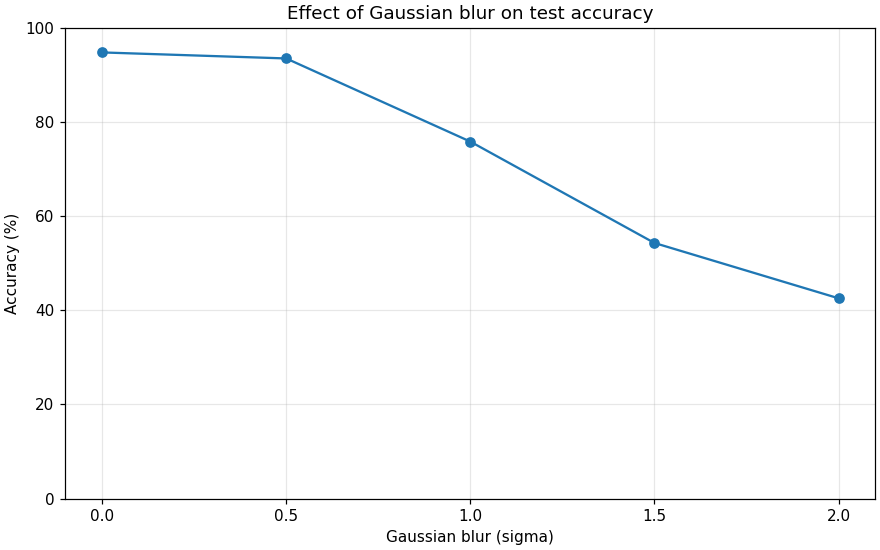

In [4]:
def blur_images(images, sigma):
    if sigma == 0:
        return images
    return TF.gaussian_blur(images, kernel_size=[7, 7], sigma=[sigma, sigma])


blur_levels = [0, 0.5, 1.0, 1.5, 2.0]
blur_results = {0: baseline}
for sigma in blur_levels[1:]:
    blur_results[sigma] = evaluate(lambda images: blur_images(images, sigma))

blur_accuracies = [blur_results[sigma]["accuracy"] for sigma in blur_levels]
for sigma, accuracy in zip(blur_levels, blur_accuracies):
    print(f"Blur sigma {sigma}: {accuracy:.2f}%")

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.plot(blur_levels, blur_accuracies, marker="o")
ax.set(
    title="Effect of Gaussian blur on test accuracy",
    xlabel="Gaussian blur (sigma)",
    ylabel="Accuracy (%)",
    ylim=(0, 100),
    xticks=blur_levels,
)
ax.grid(alpha=0.3)
plt.show()

## Accuracy by clothing class

Overall accuracy can hide how differently individual classes respond to blur. Each line shows the percentage of images the model classified correctly among the test images belonging to that class.

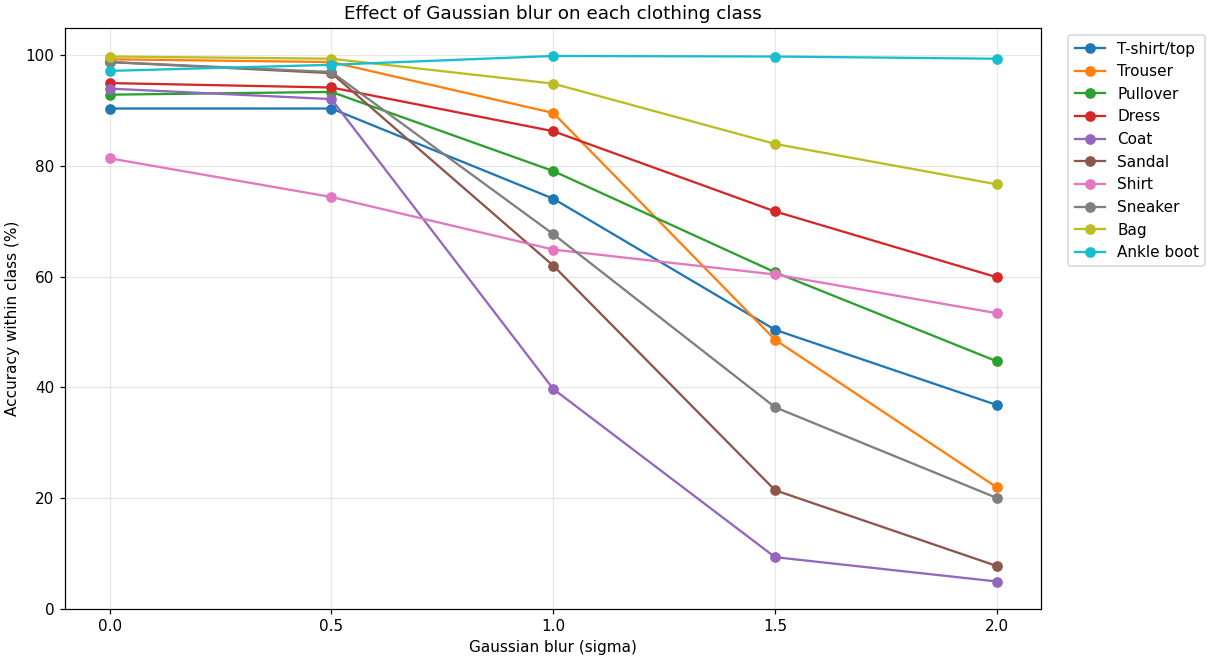

In [5]:
class_ids = range(len(class_names))
class_masks = [true_labels == class_id for class_id in class_ids]

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
for name, mask in zip(class_names, class_masks):
    accuracies = [100 * blur_results[sigma]["correct"][mask].mean() for sigma in blur_levels]
    ax.plot(blur_levels, accuracies, marker="o", label=name)

ax.set(
    title="Effect of Gaussian blur on each clothing class",
    xlabel="Gaussian blur (sigma)",
    ylabel="Accuracy within class (%)",
    ylim=(0, 105),
    xticks=blur_levels,
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.show()

## Confusion matrices and common errors

Each row represents the true class and each column represents the predicted class. The colors show percentages within each true class. Values on the diagonal are correct predictions, while values elsewhere show which classes the model mixes up. Cells at 5% or higher are labeled. Below the plots, we list the ten most common mistakes at the strongest blur level.

Top 10 classification errors at sigma 2.0
Sandal → Ankle boot: 476 images
Sneaker → Bag: 418 images
Coat → Shirt: 418 images
Sandal → Bag: 411 images
Pullover → Shirt: 410 images
Coat → Pullover: 409 images
Sneaker → Ankle boot: 382 images
Trouser → Shirt: 333 images
T-shirt/top → Pullover: 297 images
Trouser → Dress: 251 images


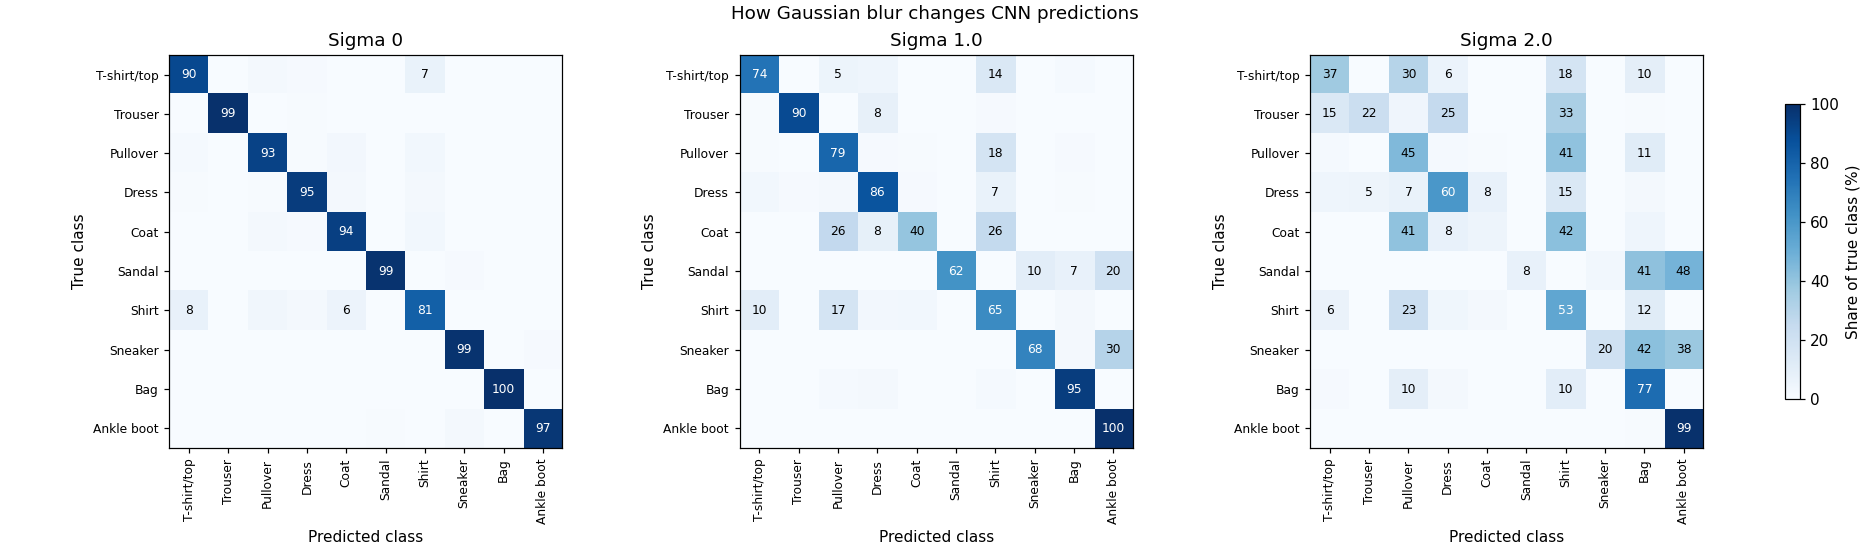

In [6]:
selected_blurs = [0, 1.0, 2.0]
confusion_matrices = {
    sigma: confusion_matrix(true_labels, blur_results[sigma]["predictions"], labels=class_ids)
    for sigma in selected_blurs
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
for ax, sigma in zip(axes, selected_blurs):
    counts = confusion_matrices[sigma]
    percentages = 100 * counts / counts.sum(axis=1, keepdims=True)
    heatmap = ax.imshow(percentages, cmap="Blues", vmin=0, vmax=100)

    ax.set(title=f"Sigma {sigma}", xlabel="Predicted class", ylabel="True class")
    ax.set_xticks(class_ids, class_names, rotation=90, fontsize=8)
    ax.set_yticks(class_ids, class_names, fontsize=8)
    for row, col in np.argwhere(percentages >= 5):
        value = percentages[row, col]
        ax.text(
            col, row, f"{value:.0f}", ha="center", va="center",
            fontsize=8, color="white" if value > 50 else "black",
        )

fig.suptitle("How Gaussian blur changes CNN predictions")
fig.colorbar(heatmap, ax=axes, shrink=0.75, label="Share of true class (%)")
plt.show()

strongest_blur = selected_blurs[-1]
counts = confusion_matrices[strongest_blur]
errors = sorted(
    (
        (counts[row, col], class_names[row], class_names[col])
        for row, col in np.argwhere(counts > 0)
        if row != col
    ),
    reverse=True,
)
print(f"Top 10 classification errors at sigma {strongest_blur}")
for count, true_name, predicted_name in errors[:10]:
    print(f"{true_name} → {predicted_name}: {count} images")

## Prediction confidence

For each image, confidence is the softmax probability assigned to the model's chosen class. We average confidence separately for correct and incorrect predictions at each selected blur level. This shows how sure the model is when it makes a mistake.

Sigma 0: correct 95.48%, incorrect 70.80%
Sigma 1.0: correct 79.21%, incorrect 60.86%
Sigma 2.0: correct 63.50%, incorrect 48.68%


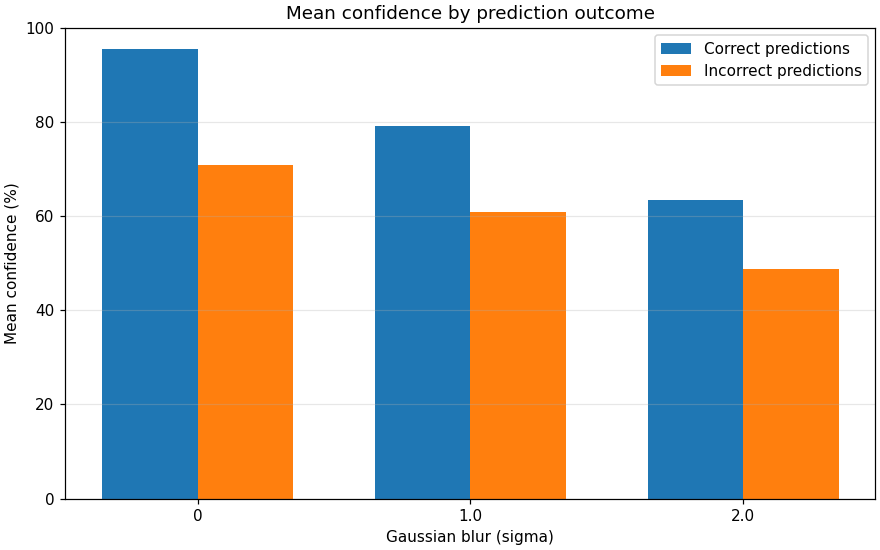

In [7]:
correct_means = []
incorrect_means = []

for sigma in selected_blurs:
    result = blur_results[sigma]
    confidence = result["confidence"]
    correct = result["correct"]
    correct_means.append(100 * confidence[correct].mean())
    incorrect_means.append(100 * confidence[~correct].mean())
    print(
        f"Sigma {sigma}: correct {correct_means[-1]:.2f}%, "
        f"incorrect {incorrect_means[-1]:.2f}%"
    )

x = np.arange(len(selected_blurs))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.bar(x - width / 2, correct_means, width, label="Correct predictions")
ax.bar(x + width / 2, incorrect_means, width, label="Incorrect predictions")
ax.set(
    title="Mean confidence by prediction outcome",
    xlabel="Gaussian blur (sigma)",
    ylabel="Mean confidence (%)",
    ylim=(0, 100),
)
ax.set_xticks(x, selected_blurs)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.show()

## Brightness and overall accuracy

We multiply each original pixel by a brightness factor, then clip it to the range 0 to 1 before normalization. Factors below 1 darken the image, and factors above 1 brighten it. A factor of 1 uses the original baseline.

Brightness 0.4: 88.77%
Brightness 0.7: 93.04%
Brightness 1.0: 94.76%
Brightness 1.3: 91.06%
Brightness 1.6: 87.01%


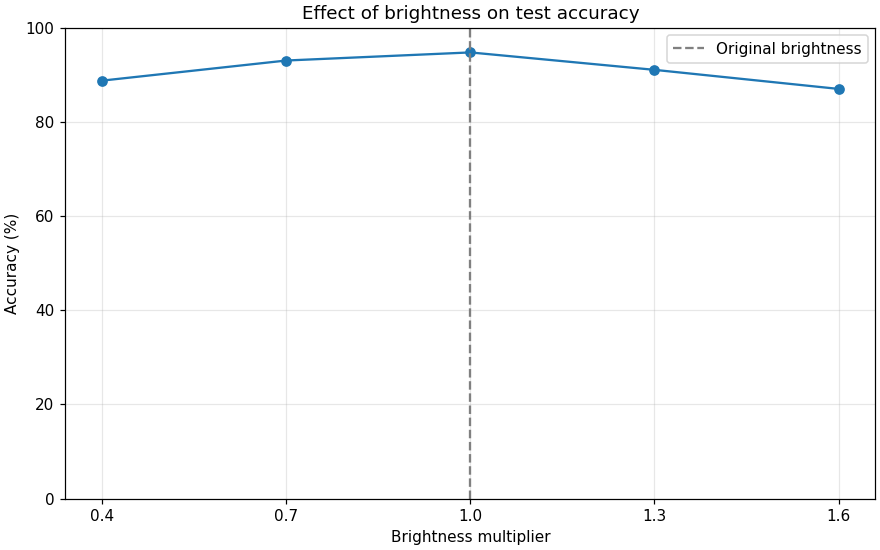

In [8]:
brightness_levels = [0.4, 0.7, 1.0, 1.3, 1.6]
brightness_accuracies = []

for factor in brightness_levels:
    if factor == 1.0:
        result = baseline
    else:
        result = evaluate(lambda images: (images * factor).clamp(0, 1))
    accuracy = result["accuracy"]
    brightness_accuracies.append(accuracy)
    print(f"Brightness {factor}: {accuracy:.2f}%")

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.plot(brightness_levels, brightness_accuracies, marker="o")
ax.axvline(1.0, color="gray", linestyle="--", label="Original brightness")
ax.set(
    title="Effect of brightness on test accuracy",
    xlabel="Brightness multiplier",
    ylabel="Accuracy (%)",
    ylim=(0, 100),
    xticks=brightness_levels,
)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Original and blurred image gallery

For each of four clothing classes, we take the first test image the CNN classified correctly at baseline. Each row shows the same image before and after blur, with its true class, predicted class, and confidence. Every image uses the same grayscale range so the columns can be compared directly.

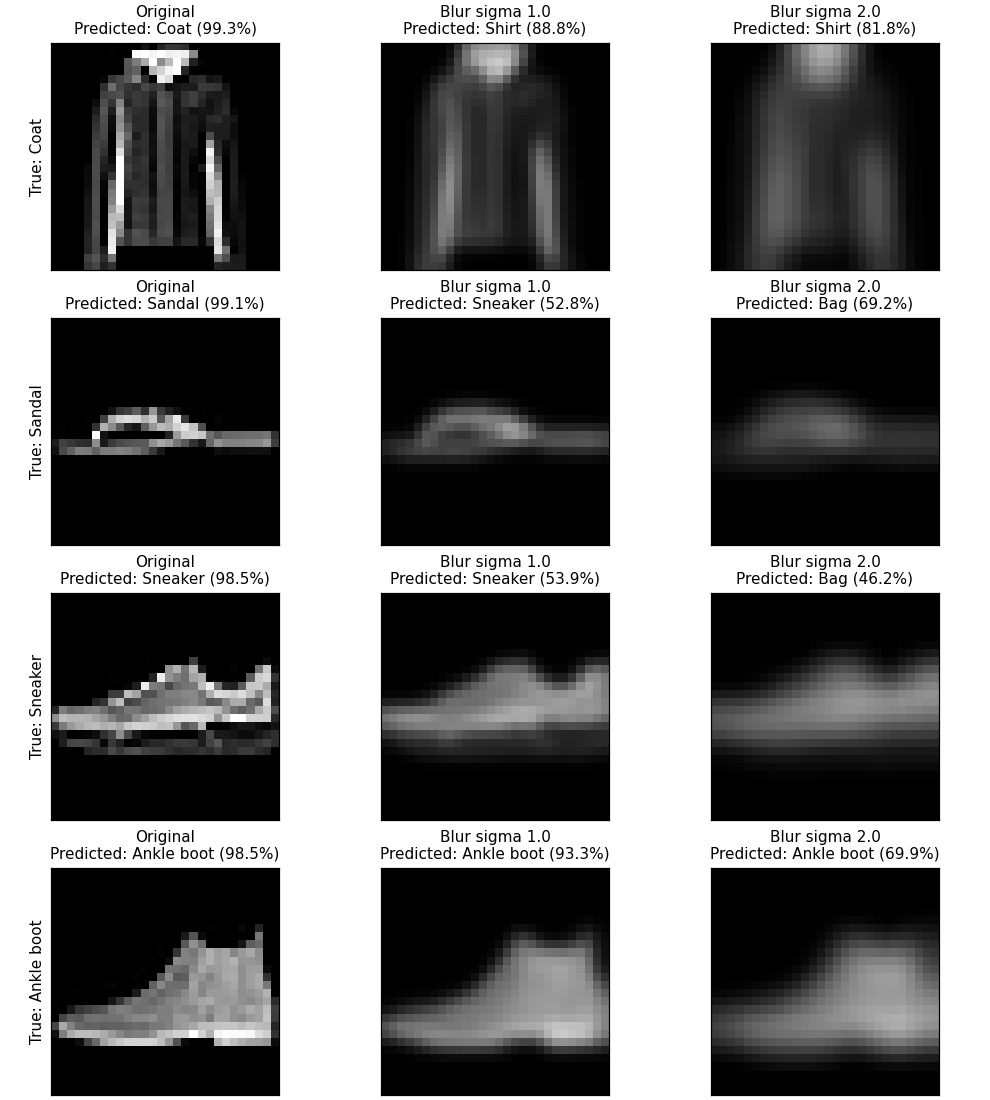

In [9]:
selected_classes = [4, 5, 7, 9]  # Coat, Sandal, Sneaker, Ankle boot

fig, axes = plt.subplots(
    len(selected_classes), len(selected_blurs), figsize=(9, 10), layout="constrained"
)
for row, class_id in enumerate(selected_classes):
    image_index = np.flatnonzero(class_masks[class_id] & baseline["correct"])[0]
    image, _ = test_dataset[image_index]

    for col, sigma in enumerate(selected_blurs):
        ax = axes[row, col]
        result = blur_results[sigma]
        predicted_name = class_names[result["predictions"][image_index]]
        confidence = 100 * result["confidence"][image_index]
        condition = "Original" if sigma == 0 else f"Blur sigma {sigma}"

        ax.imshow(blur_images(image, sigma).squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{condition}\nPredicted: {predicted_name} ({confidence:.1f}%)", fontsize=10)
        ax.set(xticks=[], yticks=[])
        if col == 0:
            ax.set_ylabel(f"True: {class_names[class_id]}", fontsize=10)

plt.show()